# A13 — Problem B Dense: MoveNet Good vs Bad Exercise Classification

This notebook solves Lab Assignment 13 for **Problem B Dense**.

The task is to classify a full exercise sequence as either:

- `1 = good exercise`
- `0 = bad exercise`

The input is based on **MoveNet 2D coordinates**.

Each sequence is cut between start and stop frames, converted into a fixed-length sequence of `c = 10` frames, min-max normalized, optionally extended with engineered features, flattened, and passed into a Dense neural network.

The notebook follows the Deep Learning steps:

1. Load and prepare movement data
2. Define Dense neural networks
3. Compile the model
4. Prepare cross-validation training and testing sets
5. Train the model
6. Evaluate predictions
7. Log experiments and final champion model in MLflow

### Imports, settings, paths

In [58]:
from pathlib import Path
import os
import random
import warnings
import json
import copy
import zipfile
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, train_test_split
try:
    from sklearn.model_selection import StratifiedGroupKFold
    HAS_STRATIFIED_GROUP_KFOLD = True
except ImportError:
    HAS_STRATIFIED_GROUP_KFOLD = False

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import mlflow
import mlflow.pytorch
from mlflow.tracking import MlflowClient

from dotenv import load_dotenv
from os import getenv

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Main sequence setup
SEQ_LEN = 10
N_SPLITS = 10
VALIDATION_SPLIT = 0.10

# Training defaults
EPOCHS = 120
PATIENCE = 15
BATCH_SIZE = 16
LEARNING_RATE = 1e-3
THRESHOLD = 0.50

NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

# Paths
# Adjust MOVENET_GOOD_BAD_DIR if your generated MoveNet CSVs are elsewhere.

#GOOD_BAD_ZIP = Path("../../../data/processed/Good_vs_Bad.zip")
#GOOD_BAD_DIR = Path("../../../data/processed/Good_vs_Bad_movenet/csv_output")

# This folder should contain MoveNet CSVs generated from the Good_vs_Bad videos.
# Expected format: one CSV per sequence, for example G01.csv, W01.csv, A1.csv.
MOVENET_GOOD_BAD_DIR = Path("../../data/processed/Good_vs_Bad_movenet/csv_output")

# Optional table with start/stop frames from your A11 start-stop model.
# Expected columns:
# sequence_id, start_frame, stop_frame
# or:
# sequence_id, pred_start, pred_stop
CUT_BOUNDS_CSV = Path("../A11/Kim/reporting/results/a11_problem_b_all_boundary_table.csv")

output_dir = Path("reporting/results")
output_dir.mkdir(parents=True, exist_ok=True)

artifact_dir = Path("reporting/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

print("DEVICE:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

#print("GOOD_BAD_ZIP:", GOOD_BAD_ZIP)
#print("GOOD_BAD_DIR:", GOOD_BAD_DIR)
print("MOVENET_GOOD_BAD_DIR:", MOVENET_GOOD_BAD_DIR)
print("CUT_BOUNDS_CSV:", CUT_BOUNDS_CSV)

DEVICE: cuda
GPU: NVIDIA GeForce RTX 2070
MOVENET_GOOD_BAD_DIR: ..\..\data\processed\Good_vs_Bad_movenet\csv_output
CUT_BOUNDS_CSV: ..\A11\Kim\reporting\results\a11_problem_b_all_boundary_table.csv


### MLFlow setup

In [59]:
load_dotenv("../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A13_problem_B_movenet_good_bad_dense"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

client = MlflowClient()

MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A13_problem_B_movenet_good_bad_dense


### Movenet loading helpers

In [60]:
FRAME_COL_CANDIDATES = [
    "frame_index",
    "frame",
    "frame_id",
    "FrameNo",
    "frame_no",
    "image_id",
]

MOVENET_TO_ASSIGNMENT = {
    "nose": "head",
    "left_shoulder": "left_shoulder",
    "left_elbow": "left_elbow",
    "right_shoulder": "right_shoulder",
    "right_elbow": "right_elbow",
    "left_wrist": "left_hand",
    "right_wrist": "right_hand",
    "left_hip": "left_hip",
    "right_hip": "right_hip",
    "left_knee": "left_knee",
    "right_knee": "right_knee",
    "left_ankle": "left_foot",
    "right_ankle": "right_foot",
}

JOINTS_13 = list(MOVENET_TO_ASSIGNMENT.values())

COORD_COLS = []
for joint in JOINTS_13:
    COORD_COLS.extend([f"{joint}_x", f"{joint}_y"])


def strip_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    return df


def find_frame_col(df: pd.DataFrame) -> str:
    for col in FRAME_COL_CANDIDATES:
        if col in df.columns:
            return col
    raise ValueError(f"No frame column found. Candidates: {FRAME_COL_CANDIDATES}")


def load_movenet_as_assignment_df(csv_path: str | Path) -> pd.DataFrame:
    """
    Converts a MoveNet CSV to the assignment's 13-joint 2D format.

    Expected MoveNet columns include:
    nose_x, nose_y, nose_score,
    left_shoulder_x, left_shoulder_y, left_shoulder_score,
    ...

    Output:
    frame_index,
    head_x, head_y, head_score,
    left_shoulder_x, left_shoulder_y, left_shoulder_score,
    ...
    """
    df = pd.read_csv(csv_path)
    df = strip_columns(df)

    frame_col = find_frame_col(df)

    out = pd.DataFrame()
    out["frame_index"] = pd.to_numeric(df[frame_col], errors="coerce").astype(int)

    if "timestamp_ms" in df.columns:
        out["timestamp_ms"] = df["timestamp_ms"]

    for movenet_joint, assignment_joint in MOVENET_TO_ASSIGNMENT.items():
        for suffix in ["x", "y", "score"]:
            src = f"{movenet_joint}_{suffix}"
            dst = f"{assignment_joint}_{suffix}"

            if src not in df.columns:
                raise ValueError(
                    f"Missing expected MoveNet column '{src}' in file: {csv_path}\n"
                    f"This notebook expects generated MoveNet CSVs, not Kinect CSVs."
                )

            out[dst] = pd.to_numeric(df[src], errors="coerce")

    out = out.sort_values("frame_index").reset_index(drop=True)
    return out


def sequence_label_from_name(sequence_id: str) -> int:
    """
    Ground truth is encoded in the filename:
    Good: A1, G*
    Bad: W*
    
    Returns:
    1 = good
    0 = bad
    """
    stem = Path(sequence_id).stem

    if stem == "A1" or stem.startswith("G"):
        return 1

    if stem.startswith("W"):
        return 0

    raise ValueError(f"Could not infer good/bad label from sequence_id: {sequence_id}")


def stem_base(path: str | Path) -> str:
    return Path(path).stem

### Start/stop loading helpers

In [61]:
def load_cut_bounds_table(cut_bounds_csv: Path) -> pd.DataFrame | None:
    """
    Loads predicted/manual start-stop frames if available.

    Supported columns:
    - sequence_id, start_frame, stop_frame
    - sequence_id, pred_start, pred_stop
    """
    if not cut_bounds_csv.exists():
        print("No cut bounds CSV found. Full sequences will be used as fallback.")
        return None

    bounds_df = pd.read_csv(cut_bounds_csv)
    bounds_df.columns = [c.strip() for c in bounds_df.columns]

    if "sequence_id" not in bounds_df.columns:
        raise ValueError("CUT_BOUNDS_CSV must contain a 'sequence_id' column.")

    if {"start_frame", "stop_frame"}.issubset(bounds_df.columns):
        bounds_df = bounds_df.rename(columns={
            "start_frame": "start_frame",
            "stop_frame": "stop_frame",
        })
    elif {"pred_start", "pred_stop"}.issubset(bounds_df.columns):
        bounds_df = bounds_df.rename(columns={
            "pred_start": "start_frame",
            "pred_stop": "stop_frame",
        })
    else:
        raise ValueError(
            "CUT_BOUNDS_CSV must contain either "
            "start_frame/stop_frame or pred_start/pred_stop."
        )

    bounds_df["sequence_id"] = bounds_df["sequence_id"].astype(str)
    bounds_df["start_frame"] = pd.to_numeric(bounds_df["start_frame"], errors="coerce")
    bounds_df["stop_frame"] = pd.to_numeric(bounds_df["stop_frame"], errors="coerce")

    bounds_df = bounds_df.dropna(subset=["start_frame", "stop_frame"]).copy()
    bounds_df["start_frame"] = bounds_df["start_frame"].astype(int)
    bounds_df["stop_frame"] = bounds_df["stop_frame"].astype(int)

    return bounds_df[["sequence_id", "start_frame", "stop_frame"]]


def get_sequence_bounds(sequence_id: str, df: pd.DataFrame, bounds_lookup: dict | None) -> tuple[int, int, str]:
    """
    Returns start/stop frames for a sequence.

    Priority:
    1. CUT_BOUNDS_CSV predictions/manual values
    2. Full sequence fallback
    """
    if bounds_lookup is not None and sequence_id in bounds_lookup:
        start_frame, stop_frame = bounds_lookup[sequence_id]
        return int(start_frame), int(stop_frame), "cut_bounds_csv"

    start_frame = int(df["frame_index"].min())
    stop_frame = int(df["frame_index"].max())
    return start_frame, stop_frame, "full_sequence_fallback"


def cut_sequence(df: pd.DataFrame, start_frame: int, stop_frame: int) -> pd.DataFrame:
    out = df[
        (df["frame_index"] >= start_frame)
        & (df["frame_index"] <= stop_frame)
    ].copy()

    out = out.sort_values("frame_index").reset_index(drop=True)
    return out

In [62]:
candidate_paths = [
    Path("../A11/Kim/reporting/results/a11_problem_b_all_boundary_table.csv"),
    Path("../A11/Kim/reporting/results/a11_problem_b_final_sequence_eval.csv"),
    Path("../A11/Kim/reporting/results/a11_problem_b_sequence_eval.csv"),
]

for p in candidate_paths:
    print(p, "exists:", p.exists())
    if p.exists():
        df_tmp = pd.read_csv(p)
        print("shape:", df_tmp.shape)
        print("columns:", df_tmp.columns.tolist())
        print(df_tmp.head())
        print()

..\A11\Kim\reporting\results\a11_problem_b_all_boundary_table.csv exists: True
shape: (179, 11)
columns: ['sequence_id', 'true_start', 'true_stop', 'pred_start', 'pred_stop', 'start_error_frames', 'stop_error_frames', 'abs_start_error_frames', 'abs_stop_error_frames', 'detected_segment', 'total_abs_error']
  sequence_id  true_start  true_stop  pred_start  pred_stop  \
0         A86           4        261          96        219   
1        A138          69        286         164        275   
2         A81          22        302          97        285   
3        A121           0        218          73        236   
4        A108         131        284         142        214   

   start_error_frames  stop_error_frames  abs_start_error_frames  \
0                  92                -42                      92   
1                  95                -11                      95   
2                  75                -17                      75   
3                  73                 18 

### Load A11 start/stop model from MLFlow

In [63]:
# Load the A11 wrapped start/stop model from MLflow.
# This should be the pyfunc model logged in A11 with run_name="problem_b_final_champion_test_eval".

A11_EXPERIMENT_NAME = "A11_movenet_exercise_frame_classification_B"
A11_RUN_NAME = "problem_b_final_champion_test_eval"

experiment = mlflow.get_experiment_by_name(A11_EXPERIMENT_NAME)

if experiment is None:
    raise RuntimeError(f"Could not find MLflow experiment: {A11_EXPERIMENT_NAME}")

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string=f"tags.mlflow.runName = '{A11_RUN_NAME}'",
    order_by=["start_time DESC"],
    max_results=1,
)

if runs.empty:
    raise RuntimeError(
        f"Could not find run_name='{A11_RUN_NAME}' in experiment '{A11_EXPERIMENT_NAME}'. "
        "Check MLflow UI and update A11_RUN_NAME or manually set A11_MODEL_URI."
    )

a11_run_id = runs.iloc[0]["run_id"]
A11_MODEL_URI = f"runs:/{a11_run_id}/model"

print("A11 run id:", a11_run_id)
print("A11 model URI:", A11_MODEL_URI)

a11_cut_model = mlflow.pyfunc.load_model(A11_MODEL_URI)

print("Loaded A11 wrapped start/stop model from MLflow.")

A11 run id: 8ed7e14daa304f3aa9537052c9bd7222
A11 model URI: runs:/8ed7e14daa304f3aa9537052c9bd7222/model


Loaded A11 wrapped start/stop model from MLflow.


### Use A11 model to create Good/bad cut bounds

In [64]:
def predict_cut_bounds_for_good_bad_csvs(
    movenet_dir: Path,
    cut_model,
    output_csv: Path,
) -> pd.DataFrame:
    rows = []

    csv_files = sorted(movenet_dir.glob("*.csv"))
    print("Found MoveNet Good/Bad CSV files:", len(csv_files))

    for csv_path in csv_files:
        sequence_id = csv_path.stem

        try:
            # Skip files that do not follow the Good/Bad naming convention.
            _ = sequence_label_from_name(sequence_id)
        except ValueError:
            continue

        raw_df = pd.read_csv(csv_path)
        raw_df.columns = [str(c).strip() for c in raw_df.columns]

        # Important: give the pyfunc wrapper a sequence_id column.
        # The A11 wrapper preserves this and groups predictions by sequence_id.
        raw_df["sequence_id"] = sequence_id

        try:
            pred_df = cut_model.predict(raw_df)

            if pred_df.empty:
                rows.append({
                    "sequence_id": sequence_id,
                    "pred_start": np.nan,
                    "pred_stop": np.nan,
                    "n_predicted_inside_windows": 0,
                    "mean_prob": np.nan,
                    "max_prob": np.nan,
                    "cut_status": "empty_prediction",
                })
                continue

            pred_start = pred_df["pred_start"].iloc[0]
            pred_stop = pred_df["pred_stop"].iloc[0]

            rows.append({
                "sequence_id": sequence_id,
                "pred_start": pred_start,
                "pred_stop": pred_stop,
                "n_predicted_inside_windows": int(pred_df["pred"].sum()),
                "mean_prob": float(pred_df["prob"].mean()),
                "max_prob": float(pred_df["prob"].max()),
                "cut_status": "ok" if pd.notna(pred_start) and pd.notna(pred_stop) else "no_positive_segment",
            })

        except Exception as e:
            rows.append({
                "sequence_id": sequence_id,
                "pred_start": np.nan,
                "pred_stop": np.nan,
                "n_predicted_inside_windows": 0,
                "mean_prob": np.nan,
                "max_prob": np.nan,
                "cut_status": f"error: {str(e)}",
            })

    bounds_df = pd.DataFrame(rows)

    output_csv.parent.mkdir(parents=True, exist_ok=True)
    bounds_df.to_csv(output_csv, index=False)

    return bounds_df


GOOD_BAD_CUT_BOUNDS_CSV = output_dir / "good_bad_start_stop_predictions_from_mlflow.csv"

good_bad_bounds_df = predict_cut_bounds_for_good_bad_csvs(
    movenet_dir=MOVENET_GOOD_BAD_DIR,
    cut_model=a11_cut_model,
    output_csv=GOOD_BAD_CUT_BOUNDS_CSV,
)

display(good_bad_bounds_df.head())
print("Saved Good/Bad cut bounds to:", GOOD_BAD_CUT_BOUNDS_CSV)

print("\nCut status distribution:")
display(good_bad_bounds_df["cut_status"].value_counts(dropna=False))

Found MoveNet Good/Bad CSV files: 114


,sequence_id,pred_start,pred_stop,n_predicted_inside_windows,mean_prob,max_prob,cut_status
0,A1,75.0,172.0,98,0.473173,1.0,ok
1,G01,68.0,159.0,92,0.408356,1.0,ok
2,G02,134.0,224.0,91,0.371590,1.0,ok
3,G03,81.0,161.0,81,0.414010,1.0,ok
4,G04,41.0,153.0,116,0.547722,1.0,ok


Saved Good/Bad cut bounds to: reporting\results\good_bad_start_stop_predictions_from_mlflow.csv

Cut status distribution:


cut_status
ok                     112
no_positive_segment      2
Name: count, dtype: int64

In [65]:
CUT_BOUNDS_CSV = GOOD_BAD_CUT_BOUNDS_CSV

print("Using generated Good/Bad cut bounds:")
print(CUT_BOUNDS_CSV)
print("Exists:", CUT_BOUNDS_CSV.exists())

Using generated Good/Bad cut bounds:
reporting\results\good_bad_start_stop_predictions_from_mlflow.csv
Exists: True


### Load all MoveNet Good/Bad sequences

In [66]:
def load_good_bad_sequences(
    movenet_dir: Path,
    cut_bounds_csv: Path,
    min_cut_frames: int = SEQ_LEN,
) -> tuple[pd.DataFrame, dict[str, pd.DataFrame]]:
    """
    Loads MoveNet CSVs, assigns good/bad labels from filenames,
    applies start/stop cutting if available, and keeps only long enough sequences.
    """
    if not movenet_dir.exists():
        raise FileNotFoundError(
            f"MoveNet directory not found: {movenet_dir}\n"
            "Generate MoveNet CSVs from Good_vs_Bad videos first, "
            "or update MOVENET_GOOD_BAD_DIR."
        )

    cut_bounds_df = load_cut_bounds_table(cut_bounds_csv)

    bounds_lookup = None
    if cut_bounds_df is not None:
        bounds_lookup = {
            row["sequence_id"]: (row["start_frame"], row["stop_frame"])
            for _, row in cut_bounds_df.iterrows()
        }

    rows = []
    sequence_dfs = {}

    csv_files = sorted(movenet_dir.glob("*.csv"))
    print("Found MoveNet CSV files:", len(csv_files))

    for csv_path in csv_files:
        sequence_id = stem_base(csv_path)

        try:
            label = sequence_label_from_name(sequence_id)
        except ValueError:
            continue

        raw_df = load_movenet_as_assignment_df(csv_path)

        start_frame, stop_frame, cut_source = get_sequence_bounds(
            sequence_id=sequence_id,
            df=raw_df,
            bounds_lookup=bounds_lookup,
        )

        cut_df = cut_sequence(raw_df, start_frame, stop_frame)

        if len(cut_df) < min_cut_frames:
            rows.append({
                "sequence_id": sequence_id,
                "path": str(csv_path),
                "label": label,
                "start_frame": start_frame,
                "stop_frame": stop_frame,
                "cut_source": cut_source,
                "n_frames_raw": len(raw_df),
                "n_frames_cut": len(cut_df),
                "kept": False,
                "reason": "too_short_after_cut",
            })
            continue

        sequence_dfs[sequence_id] = cut_df

        rows.append({
            "sequence_id": sequence_id,
            "path": str(csv_path),
            "label": label,
            "start_frame": start_frame,
            "stop_frame": stop_frame,
            "cut_source": cut_source,
            "n_frames_raw": len(raw_df),
            "n_frames_cut": len(cut_df),
            "kept": True,
            "reason": "ok",
        })

    catalog_df = pd.DataFrame(rows)

    if catalog_df.empty:
        raise RuntimeError("No valid MoveNet good/bad sequences were loaded.")

    return catalog_df, sequence_dfs


catalog_df, sequence_dfs = load_good_bad_sequences(
    movenet_dir=MOVENET_GOOD_BAD_DIR,
    cut_bounds_csv=CUT_BOUNDS_CSV,
    min_cut_frames=SEQ_LEN,
)

print("Loaded catalog:")
display(catalog_df.head())

print("Kept sequences:", int(catalog_df["kept"].sum()))
print("Dropped sequences:", int((~catalog_df["kept"]).sum()))

print("\nLabel distribution among kept sequences:")
display(catalog_df[catalog_df["kept"]]["label"].value_counts().rename(index={1: "good", 0: "bad"}))

print("\nCut source distribution:")
display(catalog_df[catalog_df["kept"]]["cut_source"].value_counts())

Found MoveNet CSV files: 114
Loaded catalog:


,sequence_id,path,label,start_frame,stop_frame,cut_source,n_frames_raw,n_frames_cut,kept,reason
0,A1,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,1,75,172,cut_bounds_csv,229,98,True,ok
1,G01,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,1,68,159,cut_bounds_csv,254,92,True,ok
2,G02,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,1,134,224,cut_bounds_csv,314,91,True,ok
3,G03,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,1,81,161,cut_bounds_csv,250,81,True,ok
4,G04,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,1,41,153,cut_bounds_csv,219,113,True,ok


Kept sequences: 112
Dropped sequences: 2

Label distribution among kept sequences:


label
good    71
bad     41
Name: count, dtype: int64


Cut source distribution:


cut_source
cut_bounds_csv            110
full_sequence_fallback      2
Name: count, dtype: int64

### Feature engineering after min-max normalization

In [67]:
SELECTED_DISTANCE_PAIRS = [
    ("left_shoulder", "right_shoulder"),
    ("left_hip", "right_hip"),
    ("left_shoulder", "left_elbow"),
    ("left_elbow", "left_hand"),
    ("right_shoulder", "right_elbow"),
    ("right_elbow", "right_hand"),
    ("left_hip", "left_knee"),
    ("left_knee", "left_foot"),
    ("right_hip", "right_knee"),
    ("right_knee", "right_foot"),
    ("left_shoulder", "left_hip"),
    ("right_shoulder", "right_hip"),
]

SELECTED_ANGLE_TRIPLES = [
    ("left_shoulder", "left_elbow", "left_hand"),
    ("right_shoulder", "right_elbow", "right_hand"),
    ("left_hip", "left_knee", "left_foot"),
    ("right_hip", "right_knee", "right_foot"),
    ("left_shoulder", "left_hip", "left_knee"),
    ("right_shoulder", "right_hip", "right_knee"),
]


def add_selected_distances(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()

    for a, b in SELECTED_DISTANCE_PAIRS:
        dx = out[f"{a}_x"] - out[f"{b}_x"]
        dy = out[f"{a}_y"] - out[f"{b}_y"]
        out[f"dist_{a}_{b}"] = np.sqrt(dx**2 + dy**2)

    return out


def calculate_angle(a: np.ndarray, b: np.ndarray, c: np.ndarray) -> np.ndarray:
    """
    Angle ABC in radians.
    """
    ba = a - b
    bc = c - b

    dot = np.sum(ba * bc, axis=1)
    norm_ba = np.linalg.norm(ba, axis=1)
    norm_bc = np.linalg.norm(bc, axis=1)

    denom = norm_ba * norm_bc
    denom = np.where(denom == 0, np.nan, denom)

    cos_angle = dot / denom
    cos_angle = np.clip(cos_angle, -1.0, 1.0)

    return np.arccos(cos_angle)


def add_selected_angles(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()

    for a, b, c in SELECTED_ANGLE_TRIPLES:
        a_xy = out[[f"{a}_x", f"{a}_y"]].to_numpy()
        b_xy = out[[f"{b}_x", f"{b}_y"]].to_numpy()
        c_xy = out[[f"{c}_x", f"{c}_y"]].to_numpy()

        out[f"angle_{a}_{b}_{c}"] = calculate_angle(a_xy, b_xy, c_xy)

    return out


def get_feature_columns(feature_set: str) -> list[str]:
    if feature_set == "coords":
        return COORD_COLS

    if feature_set == "coords_distances":
        distance_cols = [
            f"dist_{a}_{b}"
            for a, b in SELECTED_DISTANCE_PAIRS
        ]
        return COORD_COLS + distance_cols

    if feature_set == "coords_distances_angles":
        distance_cols = [
            f"dist_{a}_{b}"
            for a, b in SELECTED_DISTANCE_PAIRS
        ]
        angle_cols = [
            f"angle_{a}_{b}_{c}"
            for a, b, c in SELECTED_ANGLE_TRIPLES
        ]
        return COORD_COLS + distance_cols + angle_cols

    raise ValueError(f"Unknown feature_set: {feature_set}")


def apply_feature_engineering(norm_df: pd.DataFrame, feature_set: str) -> pd.DataFrame:
    """
    IMPORTANT:
    This is applied after min-max normalization.
    """
    out = norm_df.copy()

    if feature_set in ["coords_distances", "coords_distances_angles"]:
        out = add_selected_distances(out)

    if feature_set == "coords_distances_angles":
        out = add_selected_angles(out)

    out = out.replace([np.inf, -np.inf], np.nan)
    out = out.fillna(0.0)

    return out

### Fixed lenght sampling and fold normalization

In [68]:
def sample_fixed_length(df: pd.DataFrame, seq_len: int) -> pd.DataFrame:
    """
    Selects c frames equidistantly from the cut sequence.
    """
    if len(df) < seq_len:
        raise ValueError(f"Sequence has {len(df)} frames, but seq_len={seq_len}.")

    positions = np.linspace(0, len(df) - 1, seq_len)
    indices = np.round(positions).astype(int)

    sampled = df.iloc[indices].copy().reset_index(drop=True)
    return sampled


def fit_minmax_scaler_on_sequences(
    sequence_ids: list[str],
    sequence_dfs: dict[str, pd.DataFrame],
) -> MinMaxScaler:
    """
    Fits MinMaxScaler only on training fold coordinate columns.
    This avoids leakage from validation/test folds.
    """
    all_train_frames = []

    for sequence_id in sequence_ids:
        df = sequence_dfs[sequence_id]
        all_train_frames.append(df[COORD_COLS])

    train_coord_df = pd.concat(all_train_frames, ignore_index=True)

    scaler = MinMaxScaler()
    scaler.fit(train_coord_df)

    return scaler


def normalize_sequence_df(
    df: pd.DataFrame,
    scaler: MinMaxScaler,
) -> pd.DataFrame:
    out = df.copy()
    out[COORD_COLS] = scaler.transform(out[COORD_COLS])
    return out


def sequence_to_dense_vector(
    df: pd.DataFrame,
    scaler: MinMaxScaler,
    seq_len: int,
    feature_set: str,
) -> np.ndarray:
    """
    Pipeline for one sequence:
    1. Min-max normalize coordinates
    2. Sample fixed number of frames
    3. Add engineered features
    4. Flatten for Dense model
    """
    norm_df = normalize_sequence_df(df, scaler)
    sampled_df = sample_fixed_length(norm_df, seq_len)
    feat_df = apply_feature_engineering(sampled_df, feature_set)

    feature_cols = get_feature_columns(feature_set)
    values = feat_df[feature_cols].to_numpy(dtype=np.float32)

    return values.reshape(-1)


def build_xy_for_sequence_ids(
    sequence_ids: list[str],
    sequence_dfs: dict[str, pd.DataFrame],
    labels_lookup: dict[str, int],
    scaler: MinMaxScaler,
    seq_len: int,
    feature_set: str,
) -> tuple[np.ndarray, np.ndarray, list[str]]:
    X_rows = []
    y_rows = []
    ids = []

    for sequence_id in sequence_ids:
        dense_vector = sequence_to_dense_vector(
            df=sequence_dfs[sequence_id],
            scaler=scaler,
            seq_len=seq_len,
            feature_set=feature_set,
        )

        X_rows.append(dense_vector)
        y_rows.append(labels_lookup[sequence_id])
        ids.append(sequence_id)

    X = np.stack(X_rows).astype(np.float32)
    y = np.array(y_rows, dtype=np.float32)

    return X, y, ids

### Dataset, model, training helpers

In [69]:
class DenseSequenceDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class DenseGoodBadClassifier(nn.Module):
    def __init__(
        self,
        input_dim: int,
        hidden_dims: tuple[int, ...] = (32, 32),
        dropout: float = 0.10,
    ):
        super().__init__()

        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())

            if dropout > 0:
                layers.append(nn.Dropout(dropout))

            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        logits = self.network(x).squeeze(-1)
        return logits


def count_trainable_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def make_loader(
    X: np.ndarray,
    y: np.ndarray,
    batch_size: int,
    shuffle: bool,
) -> DataLoader:
    dataset = DenseSequenceDataset(X, y)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )

    return loader


def evaluate_model(
    model: nn.Module,
    loader: DataLoader,
    threshold: float = THRESHOLD,
) -> dict:
    model.eval()

    all_probs = []
    all_preds = []
    all_true = []
    total_loss = 0.0
    n_samples = 0

    criterion = nn.BCEWithLogitsLoss()

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            probs = torch.sigmoid(logits).detach().cpu().numpy()
            preds = (probs >= threshold).astype(int)

            all_probs.extend(probs.tolist())
            all_preds.extend(preds.tolist())
            all_true.extend(y_batch.detach().cpu().numpy().astype(int).tolist())

            total_loss += loss.item() * len(X_batch)
            n_samples += len(X_batch)

    y_true = np.array(all_true)
    y_pred = np.array(all_preds)
    y_prob = np.array(all_probs)

    if len(np.unique(y_true)) == 2:
        auc = roc_auc_score(y_true, y_prob)
    else:
        auc = np.nan

    metrics = {
        "loss": total_loss / max(n_samples, 1),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "auc": auc,
        "tp": int(((y_true == 1) & (y_pred == 1)).sum()),
        "fp": int(((y_true == 0) & (y_pred == 1)).sum()),
        "tn": int(((y_true == 0) & (y_pred == 0)).sum()),
        "fn": int(((y_true == 1) & (y_pred == 0)).sum()),
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob,
    }

    return metrics


def train_one_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    learning_rate: float,
    epochs: int,
    patience: int,
) -> tuple[nn.Module, pd.DataFrame, dict]:
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    best_epoch = -1
    patience_counter = 0

    history = []

    for epoch in range(epochs):
        model.train()

        train_loss_sum = 0.0
        n_train = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * len(X_batch)
            n_train += len(X_batch)

        train_loss = train_loss_sum / max(n_train, 1)

        train_metrics = evaluate_model(model, train_loader)
        val_metrics = evaluate_model(model, val_loader)

        row = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_metrics["accuracy"],
            "train_precision": train_metrics["precision"],
            "train_recall": train_metrics["recall"],
            "train_f1": train_metrics["f1"],
            "train_auc": train_metrics["auc"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
            "val_f1": val_metrics["f1"],
            "val_auc": val_metrics["auc"],
        }
        history.append(row)

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    model.load_state_dict(best_state)

    summary = {
        "best_val_loss": float(best_val_loss),
        "best_epoch": int(best_epoch),
        "epochs_ran": len(history),
    }

    history_df = pd.DataFrame(history)
    return model, history_df, summary

### Augmentation helpers for final champion only

In [70]:
def transform_coords_2d(
    df: pd.DataFrame,
    mirror_x: bool = False,
    scale_x: float = 1.0,
    scale_y: float = 1.0,
    rotation_degrees: float = 0.0,
    jitter_std: float = 0.0,
) -> pd.DataFrame:
    """
    Applies 2D augmentation to already min-max normalized coordinates.
    """
    out = df.copy()

    theta = np.deg2rad(rotation_degrees)
    rotation_matrix = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta),  np.cos(theta)],
    ])

    for joint in JOINTS_13:
        xy = out[[f"{joint}_x", f"{joint}_y"]].to_numpy(dtype=np.float32)

        # Center around 0.5 because min-max coordinates are typically in [0, 1]
        xy = xy - 0.5

        if mirror_x:
            xy[:, 0] = -xy[:, 0]

        xy[:, 0] *= scale_x
        xy[:, 1] *= scale_y

        xy = xy @ rotation_matrix.T

        if jitter_std > 0:
            xy += np.random.normal(0.0, jitter_std, size=xy.shape)

        xy = xy + 0.5

        out[f"{joint}_x"] = xy[:, 0]
        out[f"{joint}_y"] = xy[:, 1]

    return out


def make_max_augmentation_versions(norm_df: pd.DataFrame) -> list[tuple[str, pd.DataFrame]]:
    """
    Cascade-style augmentation.
    Each step doubles the dataset size.
    1 original -> 32 versions.

    Adapted to 2D MoveNet:
    1. mirror x
    2. stretch x
    3. stretch y
    4. rotate positive
    5. rotate negative
    """
    versions = [("original", norm_df)]

    steps = [
        ("mirror_x", lambda d: transform_coords_2d(d, mirror_x=True)),
        ("scale_x_1_05", lambda d: transform_coords_2d(d, scale_x=1.05)),
        ("scale_y_1_05", lambda d: transform_coords_2d(d, scale_y=1.05)),
        ("rotate_pos_5", lambda d: transform_coords_2d(d, rotation_degrees=5.0)),
        ("rotate_neg_5", lambda d: transform_coords_2d(d, rotation_degrees=-5.0)),
    ]

    for step_name, step_fn in steps:
        new_versions = []

        for version_name, version_df in versions:
            augmented_df = step_fn(version_df)
            new_versions.append((f"{version_name}+{step_name}", augmented_df))

        versions = versions + new_versions

    return versions


def build_augmented_train_xy(
    sequence_ids: list[str],
    sequence_dfs: dict[str, pd.DataFrame],
    labels_lookup: dict[str, int],
    scaler: MinMaxScaler,
    seq_len: int,
    feature_set: str,
    use_max_augmentation: bool,
) -> tuple[np.ndarray, np.ndarray, list[str]]:
    X_rows = []
    y_rows = []
    ids = []

    for sequence_id in sequence_ids:
        raw_df = sequence_dfs[sequence_id]
        norm_df = normalize_sequence_df(raw_df, scaler)

        if use_max_augmentation:
            versions = make_max_augmentation_versions(norm_df)
        else:
            versions = [("original", norm_df)]

        for aug_name, aug_df in versions:
            sampled_df = sample_fixed_length(aug_df, seq_len)
            feat_df = apply_feature_engineering(sampled_df, feature_set)
            feature_cols = get_feature_columns(feature_set)

            values = feat_df[feature_cols].to_numpy(dtype=np.float32)
            dense_vector = values.reshape(-1)

            X_rows.append(dense_vector)
            y_rows.append(labels_lookup[sequence_id])
            ids.append(f"{sequence_id}::{aug_name}")

    X = np.stack(X_rows).astype(np.float32)
    y = np.array(y_rows, dtype=np.float32)

    return X, y, ids

### Prepare sequence labels and CV splitter

In [71]:
kept_catalog_df = catalog_df[catalog_df["kept"]].copy().reset_index(drop=True)

sequence_ids_all = kept_catalog_df["sequence_id"].tolist()
labels_lookup = dict(zip(kept_catalog_df["sequence_id"], kept_catalog_df["label"]))

X_dummy = np.zeros(len(sequence_ids_all))
y_all = kept_catalog_df["label"].to_numpy()
groups_all = kept_catalog_df["sequence_id"].to_numpy()

print("Number of kept original sequences:", len(sequence_ids_all))
print("Good sequences:", int((y_all == 1).sum()))
print("Bad sequences:", int((y_all == 0).sum()))

if HAS_STRATIFIED_GROUP_KFOLD:
    cv_splitter = StratifiedGroupKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_SEED,
    )
    cv_splits = list(cv_splitter.split(X_dummy, y_all, groups_all))
    print("Using StratifiedGroupKFold.")
else:
    cv_splitter = GroupKFold(n_splits=N_SPLITS)
    cv_splits = list(cv_splitter.split(X_dummy, y_all, groups_all))
    print("Using GroupKFold.")

print("Number of CV folds:", len(cv_splits))

Number of kept original sequences: 112
Good sequences: 71
Bad sequences: 41
Using StratifiedGroupKFold.
Number of CV folds: 10


### Cross validation experiment function

In [72]:
def make_group_train_val_split(
    train_val_sequence_ids: list[str],
    labels_lookup: dict[str, int],
    validation_split: float,
    random_state: int,
) -> tuple[list[str], list[str]]:
    labels = np.array([labels_lookup[sid] for sid in train_val_sequence_ids])

    train_ids, val_ids = train_test_split(
        train_val_sequence_ids,
        test_size=validation_split,
        random_state=random_state,
        stratify=labels if len(np.unique(labels)) == 2 else None,
    )

    return list(train_ids), list(val_ids)


def run_cv_experiment(
    config: dict,
    run_name: str,
    use_max_augmentation: bool = False,
    log_to_mlflow: bool = True,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    fold_rows = []
    history_rows = []

    with mlflow.start_run(run_name=run_name) if log_to_mlflow else nullcontext():
        if log_to_mlflow:
            mlflow.log_param("problem", "B")
            mlflow.log_param("input_type", "MoveNet_2D")
            mlflow.log_param("model_family", "Dense")
            mlflow.log_param("task", "good_vs_bad_sequence_classification")
            mlflow.log_param("seq_len", config["seq_len"])
            mlflow.log_param("feature_set", config["feature_set"])
            mlflow.log_param("hidden_dims", str(config["hidden_dims"]))
            mlflow.log_param("dropout", config["dropout"])
            mlflow.log_param("batch_size", config["batch_size"])
            mlflow.log_param("learning_rate", config["learning_rate"])
            mlflow.log_param("epochs", config["epochs"])
            mlflow.log_param("patience", config["patience"])
            mlflow.log_param("threshold", config["threshold"])
            mlflow.log_param("use_max_augmentation", use_max_augmentation)
            mlflow.log_param("normalization", "MinMaxScaler fit on training fold only")
            mlflow.log_param("n_original_sequences", len(sequence_ids_all))

        for fold_idx, (train_val_idx, test_idx) in enumerate(cv_splits, start=1):
            train_val_ids = kept_catalog_df.iloc[train_val_idx]["sequence_id"].tolist()
            test_ids = kept_catalog_df.iloc[test_idx]["sequence_id"].tolist()

            train_ids, val_ids = make_group_train_val_split(
                train_val_sequence_ids=train_val_ids,
                labels_lookup=labels_lookup,
                validation_split=VALIDATION_SPLIT,
                random_state=RANDOM_SEED + fold_idx,
            )

            scaler = fit_minmax_scaler_on_sequences(
                sequence_ids=train_ids,
                sequence_dfs=sequence_dfs,
            )

            X_train, y_train, train_aug_ids = build_augmented_train_xy(
                sequence_ids=train_ids,
                sequence_dfs=sequence_dfs,
                labels_lookup=labels_lookup,
                scaler=scaler,
                seq_len=config["seq_len"],
                feature_set=config["feature_set"],
                use_max_augmentation=use_max_augmentation,
            )

            X_val, y_val, val_ids_used = build_xy_for_sequence_ids(
                sequence_ids=val_ids,
                sequence_dfs=sequence_dfs,
                labels_lookup=labels_lookup,
                scaler=scaler,
                seq_len=config["seq_len"],
                feature_set=config["feature_set"],
            )

            X_test, y_test, test_ids_used = build_xy_for_sequence_ids(
                sequence_ids=test_ids,
                sequence_dfs=sequence_dfs,
                labels_lookup=labels_lookup,
                scaler=scaler,
                seq_len=config["seq_len"],
                feature_set=config["feature_set"],
            )

            input_dim = X_train.shape[1]

            model = DenseGoodBadClassifier(
                input_dim=input_dim,
                hidden_dims=config["hidden_dims"],
                dropout=config["dropout"],
            ).to(DEVICE)

            n_params = count_trainable_parameters(model)

            train_loader = make_loader(
                X_train,
                y_train,
                batch_size=config["batch_size"],
                shuffle=True,
            )

            val_loader = make_loader(
                X_val,
                y_val,
                batch_size=config["batch_size"],
                shuffle=False,
            )

            test_loader = make_loader(
                X_test,
                y_test,
                batch_size=config["batch_size"],
                shuffle=False,
            )

            model, history_df, train_summary = train_one_model(
                model=model,
                train_loader=train_loader,
                val_loader=val_loader,
                learning_rate=config["learning_rate"],
                epochs=config["epochs"],
                patience=config["patience"],
            )

            train_metrics = evaluate_model(model, train_loader, threshold=config["threshold"])
            val_metrics = evaluate_model(model, val_loader, threshold=config["threshold"])
            test_metrics = evaluate_model(model, test_loader, threshold=config["threshold"])

            fold_row = {
                "run_name": run_name,
                "fold": fold_idx,
                "feature_set": config["feature_set"],
                "hidden_dims": str(config["hidden_dims"]),
                "dropout": config["dropout"],
                "batch_size": config["batch_size"],
                "learning_rate": config["learning_rate"],
                "seq_len": config["seq_len"],
                "use_max_augmentation": use_max_augmentation,
                "input_dim": input_dim,
                "n_parameters": n_params,
                "n_train_original_sequences": len(train_ids),
                "n_train_samples_after_augmentation": len(X_train),
                "n_val_sequences": len(val_ids),
                "n_test_sequences": len(test_ids),
                "best_val_loss": train_summary["best_val_loss"],
                "best_epoch": train_summary["best_epoch"],
                "epochs_ran": train_summary["epochs_ran"],
                "train_accuracy": train_metrics["accuracy"],
                "train_precision": train_metrics["precision"],
                "train_recall": train_metrics["recall"],
                "train_f1": train_metrics["f1"],
                "train_auc": train_metrics["auc"],
                "val_accuracy": val_metrics["accuracy"],
                "val_precision": val_metrics["precision"],
                "val_recall": val_metrics["recall"],
                "val_f1": val_metrics["f1"],
                "val_auc": val_metrics["auc"],
                "test_accuracy": test_metrics["accuracy"],
                "test_precision": test_metrics["precision"],
                "test_recall": test_metrics["recall"],
                "test_f1": test_metrics["f1"],
                "test_auc": test_metrics["auc"],
                "test_tp": test_metrics["tp"],
                "test_fp": test_metrics["fp"],
                "test_tn": test_metrics["tn"],
                "test_fn": test_metrics["fn"],
            }

            fold_rows.append(fold_row)

            history_df = history_df.copy()
            history_df["run_name"] = run_name
            history_df["fold"] = fold_idx
            history_rows.append(history_df)

            print(
                f"{run_name} | fold {fold_idx}/{N_SPLITS} | "
                f"test acc={test_metrics['accuracy']:.3f}, "
                f"precision={test_metrics['precision']:.3f}, "
                f"recall={test_metrics['recall']:.3f}, "
                f"f1={test_metrics['f1']:.3f}, "
                f"params={n_params}"
            )

        fold_df = pd.DataFrame(fold_rows)
        history_all_df = pd.concat(history_rows, ignore_index=True)

        summary = fold_df.select_dtypes(include=[np.number]).mean(numeric_only=True)

        if log_to_mlflow:
            for metric_name in [
                "test_accuracy",
                "test_precision",
                "test_recall",
                "test_f1",
                "test_auc",
                "val_accuracy",
                "val_precision",
                "val_recall",
                "val_f1",
                "val_auc",
                "n_parameters",
            ]:
                if metric_name in summary.index:
                    mlflow.log_metric(f"cv_mean_{metric_name}", float(summary[metric_name]))

            for metric_name in [
                "test_accuracy",
                "test_precision",
                "test_recall",
                "test_f1",
                "test_auc",
            ]:
                if metric_name in fold_df.columns:
                    mlflow.log_metric(f"cv_std_{metric_name}", float(fold_df[metric_name].std()))

            fold_path = output_dir / f"{run_name}_fold_results.csv"
            history_path = output_dir / f"{run_name}_history.csv"

            fold_df.to_csv(fold_path, index=False)
            history_all_df.to_csv(history_path, index=False)

            mlflow.log_artifact(str(fold_path))
            mlflow.log_artifact(str(history_path))

    return fold_df, history_all_df


# Needed because run_cv_experiment optionally uses a dummy context
from contextlib import nullcontext

### Hyperparameter search configs without augmentation

In [73]:
DENSE_CONFIGS = [
    {
        "name": "dense_coords_32_32_drop010",
        "seq_len": SEQ_LEN,
        "feature_set": "coords",
        "hidden_dims": (32, 32),
        "dropout": 0.10,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
        "threshold": THRESHOLD,
    },
    {
        "name": "dense_coords_32_16_drop010",
        "seq_len": SEQ_LEN,
        "feature_set": "coords",
        "hidden_dims": (32, 16),
        "dropout": 0.10,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
        "threshold": THRESHOLD,
    },
    {
        "name": "dense_coords_64_drop020",
        "seq_len": SEQ_LEN,
        "feature_set": "coords",
        "hidden_dims": (64,),
        "dropout": 0.20,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
        "threshold": THRESHOLD,
    },
    {
        "name": "dense_coords_dist_24_12_drop010",
        "seq_len": SEQ_LEN,
        "feature_set": "coords_distances",
        "hidden_dims": (24, 12),
        "dropout": 0.10,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
        "threshold": THRESHOLD,
    },
    {
        "name": "dense_coords_dist_ang_16_8_drop010",
        "seq_len": SEQ_LEN,
        "feature_set": "coords_distances_angles",
        "hidden_dims": (16, 8),
        "dropout": 0.10,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
        "threshold": THRESHOLD,
    },
    {
        "name": "dense_coords_32_32_drop020_lr5e4",
        "seq_len": SEQ_LEN,
        "feature_set": "coords",
        "hidden_dims": (32, 32),
        "dropout": 0.20,
        "batch_size": 16,
        "learning_rate": 5e-4,
        "epochs": EPOCHS,
        "patience": PATIENCE,
        "threshold": THRESHOLD,
    },
]

### Run hyperparameter search without augmentation

In [74]:
all_search_folds = []
all_search_histories = []

for config in DENSE_CONFIGS:
    run_name = f"a13_no_aug_{config['name']}"

    fold_df, history_df = run_cv_experiment(
        config=config,
        run_name=run_name,
        use_max_augmentation=False,
        log_to_mlflow=True,
    )

    all_search_folds.append(fold_df)
    all_search_histories.append(history_df)

search_results_df = pd.concat(all_search_folds, ignore_index=True)
search_history_df = pd.concat(all_search_histories, ignore_index=True)

search_results_path = output_dir / "a13_dense_no_aug_hyperparameter_search_folds.csv"
search_results_df.to_csv(search_results_path, index=False)

display(search_results_df.head())
print("Saved:", search_results_path)

a13_no_aug_dense_coords_32_32_drop010 | fold 1/10 | test acc=0.667, precision=0.667, recall=1.000, f1=0.800, params=9441
a13_no_aug_dense_coords_32_32_drop010 | fold 2/10 | test acc=0.917, precision=0.875, recall=1.000, f1=0.933, params=9441
a13_no_aug_dense_coords_32_32_drop010 | fold 3/10 | test acc=1.000, precision=1.000, recall=1.000, f1=1.000, params=9441
a13_no_aug_dense_coords_32_32_drop010 | fold 4/10 | test acc=0.909, precision=0.875, recall=1.000, f1=0.933, params=9441
a13_no_aug_dense_coords_32_32_drop010 | fold 5/10 | test acc=0.727, precision=0.700, recall=1.000, f1=0.824, params=9441
a13_no_aug_dense_coords_32_32_drop010 | fold 6/10 | test acc=0.909, precision=0.875, recall=1.000, f1=0.933, params=9441
a13_no_aug_dense_coords_32_32_drop010 | fold 7/10 | test acc=0.636, precision=0.636, recall=1.000, f1=0.778, params=9441
a13_no_aug_dense_coords_32_32_drop010 | fold 8/10 | test acc=0.727, precision=0.750, recall=0.857, f1=0.800, params=9441
a13_no_aug_dense_coords_32_32_dr

,run_name,fold,feature_set,hidden_dims,dropout,batch_size,learning_rate,seq_len,use_max_augmentation,input_dim,...,val_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc,test_tp,test_fp,test_tn,test_fn
0,a13_no_aug_dense_coords_32_32_drop010,1,coords,"(32, 32)",0.1,16,0.001,10,False,260,...,1.000000,0.666667,0.666667,1.0,0.800000,0.687500,8,4,0,0
1,a13_no_aug_dense_coords_32_32_drop010,2,coords,"(32, 32)",0.1,16,0.001,10,False,260,...,0.833333,0.916667,0.875000,1.0,0.933333,1.000000,7,1,4,0
2,a13_no_aug_dense_coords_32_32_drop010,3,coords,"(32, 32)",0.1,16,0.001,10,False,260,...,1.000000,1.000000,1.000000,1.0,1.000000,1.000000,7,0,4,0
3,a13_no_aug_dense_coords_32_32_drop010,4,coords,"(32, 32)",0.1,16,0.001,10,False,260,...,0.821429,0.909091,0.875000,1.0,0.933333,0.857143,7,1,3,0
4,a13_no_aug_dense_coords_32_32_drop010,5,coords,"(32, 32)",0.1,16,0.001,10,False,260,...,0.750000,0.727273,0.700000,1.0,0.823529,0.964286,7,3,1,0


Saved: reporting\results\a13_dense_no_aug_hyperparameter_search_folds.csv


### Summarize hyperparameter search

In [75]:
summary_cols = [
    "run_name",
    "feature_set",
    "hidden_dims",
    "dropout",
    "batch_size",
    "learning_rate",
    "input_dim",
    "n_parameters",
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1",
    "test_auc",
    "best_epoch",
]

search_summary_df = (
    search_results_df[summary_cols]
    .groupby(["run_name", "feature_set", "hidden_dims", "dropout", "batch_size", "learning_rate"], as_index=False)
    .agg(
        input_dim=("input_dim", "mean"),
        n_parameters=("n_parameters", "mean"),
        mean_test_accuracy=("test_accuracy", "mean"),
        std_test_accuracy=("test_accuracy", "std"),
        mean_test_precision=("test_precision", "mean"),
        std_test_precision=("test_precision", "std"),
        mean_test_recall=("test_recall", "mean"),
        std_test_recall=("test_recall", "std"),
        mean_test_f1=("test_f1", "mean"),
        std_test_f1=("test_f1", "std"),
        mean_test_auc=("test_auc", "mean"),
        std_test_auc=("test_auc", "std"),
        mean_best_epoch=("best_epoch", "mean"),
    )
    .sort_values(["mean_test_f1", "mean_test_accuracy"], ascending=False)
)

summary_path = output_dir / "a13_dense_no_aug_hyperparameter_search_summary.csv"
search_summary_df.to_csv(summary_path, index=False)

display(search_summary_df)

print("Saved:", summary_path)

,run_name,feature_set,hidden_dims,dropout,batch_size,learning_rate,input_dim,n_parameters,mean_test_accuracy,std_test_accuracy,mean_test_precision,std_test_precision,mean_test_recall,std_test_recall,mean_test_f1,std_test_f1,mean_test_auc,std_test_auc,mean_best_epoch
4,a13_no_aug_dense_coords_dist_24_12_drop010,coords_distances,"(24, 12)",0.1,16,0.0010,380.0,9457.0,0.890909,0.119687,0.884470,0.134384,0.985714,0.045175,0.925919,0.075821,0.957143,0.064769,82.9
5,a13_no_aug_dense_coords_dist_ang_16_8_drop010,coords_distances_angles,"(16, 8)",0.1,16,0.0010,440.0,7201.0,0.883333,0.122009,0.887500,0.107274,0.942857,0.099887,0.911874,0.093762,0.947366,0.063470,62.8
1,a13_no_aug_dense_coords_32_32_drop010,coords,"(32, 32)",0.1,16,0.0010,260.0,9441.0,0.831061,0.134672,0.823517,0.129814,0.971429,0.060234,0.885845,0.084296,0.897321,0.114128,80.3
2,a13_no_aug_dense_coords_32_32_drop020_lr5e4,coords,"(32, 32)",0.2,16,0.0005,260.0,9441.0,0.821970,0.138648,0.807803,0.134710,0.985714,0.045175,0.882484,0.086216,0.874554,0.155624,91.8
0,a13_no_aug_dense_coords_32_16_drop010,coords,"(32, 16)",0.1,16,0.0010,260.0,8897.0,0.821970,0.131858,0.808795,0.132828,0.985714,0.045175,0.882365,0.080421,0.856696,0.152578,77.1
3,a13_no_aug_dense_coords_64_drop020,coords,"(64,)",0.2,16,0.0010,260.0,16769.0,0.812879,0.135239,0.806017,0.133836,0.971429,0.060234,0.874865,0.084574,0.897321,0.111617,84.6


Saved: reporting\results\a13_dense_no_aug_hyperparameter_search_summary.csv


### Select champion config from no-augmentation search

In [76]:
best_run_name = search_summary_df.iloc[0]["run_name"]
print("Best no-augmentation run:", best_run_name)

best_config_name = best_run_name.replace("a13_no_aug_", "")
CHAMPION_CONFIG = None

for config in DENSE_CONFIGS:
    if config["name"] == best_config_name:
        CHAMPION_CONFIG = config.copy()
        break

if CHAMPION_CONFIG is None:
    raise RuntimeError("Could not find champion config.")

print("Selected champion config:")
print(json.dumps(CHAMPION_CONFIG, indent=2))

Best no-augmentation run: a13_no_aug_dense_coords_dist_24_12_drop010
Selected champion config:
{
  "name": "dense_coords_dist_24_12_drop010",
  "seq_len": 10,
  "feature_set": "coords_distances",
  "hidden_dims": [
    24,
    12
  ],
  "dropout": 0.1,
  "batch_size": 16,
  "learning_rate": 0.001,
  "epochs": 120,
  "patience": 15,
  "threshold": 0.5
}


### Final champion CV with maximum augmentation

In [77]:
final_aug_run_name = f"a13_final_augmented_champion_{CHAMPION_CONFIG['name']}"

final_aug_fold_df, final_aug_history_df = run_cv_experiment(
    config=CHAMPION_CONFIG,
    run_name=final_aug_run_name,
    use_max_augmentation=True,
    log_to_mlflow=True,
)

final_aug_summary_df = (
    final_aug_fold_df
    .select_dtypes(include=[np.number])
    .agg(["mean", "std"])
    .T
    .reset_index()
    .rename(columns={"index": "metric"})
)

final_aug_fold_path = output_dir / "a13_final_augmented_champion_cv_folds.csv"
final_aug_summary_path = output_dir / "a13_final_augmented_champion_cv_summary.csv"

final_aug_fold_df.to_csv(final_aug_fold_path, index=False)
final_aug_summary_df.to_csv(final_aug_summary_path, index=False)

display(final_aug_fold_df)
display(final_aug_summary_df)

print("Saved:", final_aug_fold_path)
print("Saved:", final_aug_summary_path)

a13_final_augmented_champion_dense_coords_dist_24_12_drop010 | fold 1/10 | test acc=0.917, precision=0.889, recall=1.000, f1=0.941, params=9457
a13_final_augmented_champion_dense_coords_dist_24_12_drop010 | fold 2/10 | test acc=0.917, precision=0.875, recall=1.000, f1=0.933, params=9457
a13_final_augmented_champion_dense_coords_dist_24_12_drop010 | fold 3/10 | test acc=0.909, precision=0.875, recall=1.000, f1=0.933, params=9457
a13_final_augmented_champion_dense_coords_dist_24_12_drop010 | fold 4/10 | test acc=1.000, precision=1.000, recall=1.000, f1=1.000, params=9457
a13_final_augmented_champion_dense_coords_dist_24_12_drop010 | fold 5/10 | test acc=0.818, precision=0.857, recall=0.857, f1=0.857, params=9457
a13_final_augmented_champion_dense_coords_dist_24_12_drop010 | fold 6/10 | test acc=1.000, precision=1.000, recall=1.000, f1=1.000, params=9457
a13_final_augmented_champion_dense_coords_dist_24_12_drop010 | fold 7/10 | test acc=1.000, precision=1.000, recall=1.000, f1=1.000, para

,run_name,fold,feature_set,hidden_dims,dropout,batch_size,learning_rate,seq_len,use_max_augmentation,input_dim,...,val_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc,test_tp,test_fp,test_tn,test_fn
0,a13_final_augmented_champion_dense_coords_dist...,1,coords_distances,"(24, 12)",0.1,16,0.001,10,True,380,...,0.875000,0.916667,0.888889,1.000000,0.941176,1.000000,8,1,3,0
1,a13_final_augmented_champion_dense_coords_dist...,2,coords_distances,"(24, 12)",0.1,16,0.001,10,True,380,...,0.875000,0.916667,0.875000,1.000000,0.933333,1.000000,7,1,4,0
2,a13_final_augmented_champion_dense_coords_dist...,3,coords_distances,"(24, 12)",0.1,16,0.001,10,True,380,...,1.000000,0.909091,0.875000,1.000000,0.933333,1.000000,7,1,3,0
3,a13_final_augmented_champion_dense_coords_dist...,4,coords_distances,"(24, 12)",0.1,16,0.001,10,True,380,...,0.892857,1.000000,1.000000,1.000000,1.000000,1.000000,7,0,4,0
4,a13_final_augmented_champion_dense_coords_dist...,5,coords_distances,"(24, 12)",0.1,16,0.001,10,True,380,...,0.892857,0.818182,0.857143,0.857143,0.857143,0.928571,6,1,3,1
5,a13_final_augmented_champion_dense_coords_dist...,6,coords_distances,"(24, 12)",0.1,16,0.001,10,True,380,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7,0,4,0
6,a13_final_augmented_champion_dense_coords_dist...,7,coords_distances,"(24, 12)",0.1,16,0.001,10,True,380,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7,0,4,0
7,a13_final_augmented_champion_dense_coords_dist...,8,coords_distances,"(24, 12)",0.1,16,0.001,10,True,380,...,1.000000,0.909091,0.875000,1.000000,0.933333,0.964286,7,1,3,0
8,a13_final_augmented_champion_dense_coords_dist...,9,coords_distances,"(24, 12)",0.1,16,0.001,10,True,380,...,0.964286,1.000000,1.000000,1.000000,1.000000,1.000000,7,0,4,0
9,a13_final_augmented_champion_dense_coords_dist...,10,coords_distances,"(24, 12)",0.1,16,0.001,10,True,380,...,1.000000,0.636364,0.714286,0.714286,0.714286,0.821429,5,2,2,2


,metric,mean,std
0,fold,5.500000,3.027650e+00
1,dropout,0.100000,0.000000e+00
2,batch_size,16.000000,0.000000e+00
3,learning_rate,0.001000,2.285699e-19
4,seq_len,10.000000,0.000000e+00
5,input_dim,380.000000,0.000000e+00
6,n_parameters,9457.000000,0.000000e+00
7,n_train_original_sequences,90.000000,0.000000e+00
8,n_train_samples_after_augmentation,2880.000000,0.000000e+00
9,n_val_sequences,10.800000,4.216370e-01


Saved: reporting\results\a13_final_augmented_champion_cv_folds.csv
Saved: reporting\results\a13_final_augmented_champion_cv_summary.csv


### Confusion matrix from final augmented CV

Aggregated final augmented CV confusion matrix:
[[34  7]
 [ 3 68]]


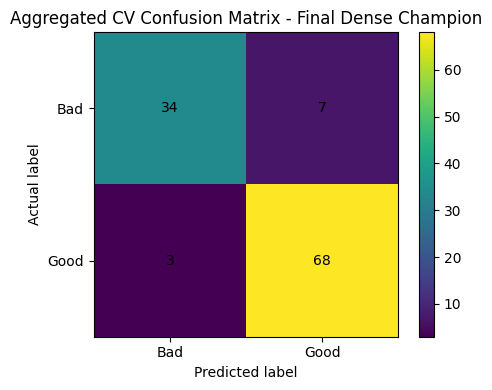

Saved: reporting\results\a13_final_augmented_champion_confusion_matrix.png


In [78]:
cv_tp = int(final_aug_fold_df["test_tp"].sum())
cv_fp = int(final_aug_fold_df["test_fp"].sum())
cv_tn = int(final_aug_fold_df["test_tn"].sum())
cv_fn = int(final_aug_fold_df["test_fn"].sum())

cm = np.array([
    [cv_tn, cv_fp],
    [cv_fn, cv_tp],
])

print("Aggregated final augmented CV confusion matrix:")
print(cm)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Aggregated CV Confusion Matrix - Final Dense Champion")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.xticks([0, 1], ["Bad", "Good"])
plt.yticks([0, 1], ["Bad", "Good"])

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()

cm_path = output_dir / "a13_final_augmented_champion_confusion_matrix.png"
plt.savefig(cm_path, dpi=150)
plt.show()

print("Saved:", cm_path)

### Train final champion model on all data and save for integration

In [79]:
def train_final_model_on_all_sequences(
    config: dict,
    use_max_augmentation: bool = True,
):
    all_ids = sequence_ids_all.copy()
    all_labels = np.array([labels_lookup[sid] for sid in all_ids])

    train_ids, val_ids = train_test_split(
        all_ids,
        test_size=VALIDATION_SPLIT,
        random_state=RANDOM_SEED,
        stratify=all_labels if len(np.unique(all_labels)) == 2 else None,
    )

    final_scaler = fit_minmax_scaler_on_sequences(
        sequence_ids=train_ids,
        sequence_dfs=sequence_dfs,
    )

    X_train, y_train, train_aug_ids = build_augmented_train_xy(
        sequence_ids=train_ids,
        sequence_dfs=sequence_dfs,
        labels_lookup=labels_lookup,
        scaler=final_scaler,
        seq_len=config["seq_len"],
        feature_set=config["feature_set"],
        use_max_augmentation=use_max_augmentation,
    )

    X_val, y_val, val_ids_used = build_xy_for_sequence_ids(
        sequence_ids=val_ids,
        sequence_dfs=sequence_dfs,
        labels_lookup=labels_lookup,
        scaler=final_scaler,
        seq_len=config["seq_len"],
        feature_set=config["feature_set"],
    )

    input_dim = X_train.shape[1]

    final_model = DenseGoodBadClassifier(
        input_dim=input_dim,
        hidden_dims=config["hidden_dims"],
        dropout=config["dropout"],
    ).to(DEVICE)

    train_loader = make_loader(
        X_train,
        y_train,
        batch_size=config["batch_size"],
        shuffle=True,
    )

    val_loader = make_loader(
        X_val,
        y_val,
        batch_size=config["batch_size"],
        shuffle=False,
    )

    final_model, final_history_df, final_train_summary = train_one_model(
        model=final_model,
        train_loader=train_loader,
        val_loader=val_loader,
        learning_rate=config["learning_rate"],
        epochs=config["epochs"],
        patience=config["patience"],
    )

    train_metrics = evaluate_model(final_model, train_loader, threshold=config["threshold"])
    val_metrics = evaluate_model(final_model, val_loader, threshold=config["threshold"])

    final_info = {
        "input_dim": input_dim,
        "n_parameters": count_trainable_parameters(final_model),
        "n_train_original_sequences": len(train_ids),
        "n_train_samples_after_augmentation": len(X_train),
        "n_val_sequences": len(val_ids),
        "best_val_loss": final_train_summary["best_val_loss"],
        "best_epoch": final_train_summary["best_epoch"],
        "epochs_ran": final_train_summary["epochs_ran"],
        "train_accuracy": train_metrics["accuracy"],
        "train_precision": train_metrics["precision"],
        "train_recall": train_metrics["recall"],
        "train_f1": train_metrics["f1"],
        "train_auc": train_metrics["auc"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
        "val_auc": val_metrics["auc"],
    }

    return final_model, final_scaler, final_history_df, final_info, train_ids, val_ids


final_model, final_scaler, final_history_df, final_info, final_train_ids, final_val_ids = train_final_model_on_all_sequences(
    config=CHAMPION_CONFIG,
    use_max_augmentation=True,
)

print("Final model info:")
print(json.dumps(final_info, indent=2))

Final model info:
{
  "input_dim": 380,
  "n_parameters": 9457,
  "n_train_original_sequences": 100,
  "n_train_samples_after_augmentation": 3200,
  "n_val_sequences": 12,
  "best_val_loss": 0.01946038380265236,
  "best_epoch": 15,
  "epochs_ran": 30,
  "train_accuracy": 0.9859375,
  "train_precision": 1.0,
  "train_recall": 0.9776785714285714,
  "train_f1": 0.9887133182844243,
  "train_auc": 1.0,
  "val_accuracy": 1.0,
  "val_precision": 1.0,
  "val_recall": 1.0,
  "val_f1": 1.0,
  "val_auc": 1.0
}


###Log final chmapion model to MLFlow

In [80]:
final_model_path = artifact_dir / "a13_final_dense_champion_model.pt"
final_scaler_path = artifact_dir / "a13_final_dense_champion_minmax_scaler.joblib"
final_config_path = artifact_dir / "a13_final_dense_champion_config.json"
final_history_path = output_dir / "a13_final_dense_champion_training_history.csv"

torch.save(final_model.state_dict(), final_model_path)
joblib.dump(final_scaler, final_scaler_path)
final_history_df.to_csv(final_history_path, index=False)

final_config_to_save = {
    **CHAMPION_CONFIG,
    "input_dim": final_info["input_dim"],
    "n_parameters": final_info["n_parameters"],
    "coord_cols": COORD_COLS,
    "joints_13": JOINTS_13,
    "selected_distance_pairs": SELECTED_DISTANCE_PAIRS,
    "selected_angle_triples": SELECTED_ANGLE_TRIPLES,
    "normalization": "MinMaxScaler fit on training data only",
    "augmentation": "max cascade augmentation for final champion training",
}

with open(final_config_path, "w") as f:
    json.dump(final_config_to_save, f, indent=2)

with mlflow.start_run(run_name=f"a13_logged_final_dense_champion_{CHAMPION_CONFIG['name']}"):
    mlflow.log_param("problem", "B")
    mlflow.log_param("input_type", "MoveNet_2D")
    mlflow.log_param("model_family", "Dense")
    mlflow.log_param("task", "good_vs_bad_sequence_classification")
    mlflow.log_param("seq_len", CHAMPION_CONFIG["seq_len"])
    mlflow.log_param("feature_set", CHAMPION_CONFIG["feature_set"])
    mlflow.log_param("hidden_dims", str(CHAMPION_CONFIG["hidden_dims"]))
    mlflow.log_param("dropout", CHAMPION_CONFIG["dropout"])
    mlflow.log_param("batch_size", CHAMPION_CONFIG["batch_size"])
    mlflow.log_param("learning_rate", CHAMPION_CONFIG["learning_rate"])
    mlflow.log_param("epochs", CHAMPION_CONFIG["epochs"])
    mlflow.log_param("patience", CHAMPION_CONFIG["patience"])
    mlflow.log_param("threshold", CHAMPION_CONFIG["threshold"])
    mlflow.log_param("input_dim", final_info["input_dim"])
    mlflow.log_param("n_parameters", final_info["n_parameters"])
    mlflow.log_param("use_max_augmentation", True)
    mlflow.log_param("normalization", "MinMaxScaler")

    for key, value in final_info.items():
        mlflow.log_metric(key, float(value))

    mlflow.log_artifact(str(final_model_path))
    mlflow.log_artifact(str(final_scaler_path))
    mlflow.log_artifact(str(final_config_path))
    mlflow.log_artifact(str(final_history_path))

    mlflow.pytorch.log_model(final_model, artifact_path="model")

print("Final champion logged to MLflow.")
print("Saved model:", final_model_path)
print("Saved scaler:", final_scaler_path)
print("Saved config:", final_config_path)

2026/05/09 13:47:07 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/09 13:47:08 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization.The recommended safe alternative is to set 'export_model' to True to save the pytorch model using the safe graph model format.
2026/05/09 13:47:08 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cu118) contains a local version label (+cu118). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/05/09 13:47:13 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cu118) contains a local version label (+cu118). ML

🏃 View run a13_logged_final_dense_champion_dense_coords_dist_24_12_drop010 at: https://172.27.62.170:5001/#/experiments/31/runs/188c84488ce24dab9be9bf212d9744e6
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/31
Final champion logged to MLflow.
Saved model: reporting\artifacts\a13_final_dense_champion_model.pt
Saved scaler: reporting\artifacts\a13_final_dense_champion_minmax_scaler.joblib
Saved config: reporting\artifacts\a13_final_dense_champion_config.json


### Prediction helper for practical uselfulness check

In [81]:
def predict_good_bad_sequence(
    model: nn.Module,
    scaler: MinMaxScaler,
    sequence_df: pd.DataFrame,
    config: dict,
    threshold: float = THRESHOLD,
) -> dict:
    model.eval()

    x_vec = sequence_to_dense_vector(
        df=sequence_df,
        scaler=scaler,
        seq_len=config["seq_len"],
        feature_set=config["feature_set"],
    )

    x_tensor = torch.tensor(x_vec.reshape(1, -1), dtype=torch.float32).to(DEVICE)

    with torch.no_grad():
        logit = model(x_tensor)
        prob_good = torch.sigmoid(logit).detach().cpu().numpy()[0]

    pred_label = int(prob_good >= threshold)

    return {
        "prob_good": float(prob_good),
        "pred_label": pred_label,
        "pred_class": "good" if pred_label == 1 else "bad",
    }


example_sequence_id = sequence_ids_all[0]
example_df = sequence_dfs[example_sequence_id]
example_true_label = labels_lookup[example_sequence_id]

example_result = predict_good_bad_sequence(
    model=final_model,
    scaler=final_scaler,
    sequence_df=example_df,
    config=CHAMPION_CONFIG,
    threshold=CHAMPION_CONFIG["threshold"],
)

print("Example sequence:", example_sequence_id)
print("True class:", "good" if example_true_label == 1 else "bad")
print("Prediction:")
print(example_result)

Example sequence: A1
True class: good
Prediction:
{'prob_good': 0.7465677261352539, 'pred_label': 1, 'pred_class': 'good'}


## Conclusion

This notebook implemented **Problem B Dense** for Lab Assignment 13.  
The task was to classify complete exercise sequences as either good or bad using **MoveNet 2D coordinates**.

### Data preparation

The input data consisted of MoveNet frame sequences extracted from the Good vs Bad exercise videos.

The labels were inferred from the filenames:

- `A1` and `G*` were labelled as good exercises.
- `W*` were labelled as bad exercises.

The A11 start/stop recognition model was loaded from MLflow and used to generate Good/Bad-specific cut bounds.  
The model produced valid start/stop predictions for 112 of 114 MoveNet CSV files.

After cutting and filtering, the final classification dataset contained:

- 112 kept sequences
- 71 good sequences
- 41 bad sequences

The dataset was therefore moderately imbalanced toward good exercises.

### Fixed-size sequence representation

Each cut sequence was converted into a fixed-length representation by selecting `c = 10` frames equidistantly between the predicted start and stop frames.

For the base coordinate representation, each frame contained:

- 13 MoveNet joints
- 2 coordinates per joint
- 26 coordinate features per frame

For the Dense model, the fixed-size frame sequence was flattened into one input vector.

### Normalization and feature engineering

Min-max normalization was applied before feature preprocessing.  
To avoid data leakage, the scaler was fitted only on the training fold and then applied to the validation and test folds.

The tested feature sets were:

- coordinates only
- coordinates + selected normalized distances
- coordinates + selected normalized distances + selected joint angles

The best final model used coordinates and selected distances.

### Hyperparameter search without augmentation

During the first search phase, no augmentation was used.  
This made the Dense variants faster to compare.

The best no-augmentation model was:

- feature set: coordinates + selected distances
- hidden layers: `(24, 12)`
- dropout: `0.10`
- learning rate: `0.001`
- batch size: `16`
- input dimension: `380`
- trainable parameters: `9457`

This model stayed below the approximate Dense parameter constraint of 10,000 parameters.

The no-augmentation champion achieved approximately:

- mean test accuracy: `0.891`
- mean test precision: `0.884`
- mean test recall: `0.986`
- mean test F1: `0.926`
- mean test AUC: `0.957`

### Final champion with augmentation

After selecting the best Dense setup, the final champion was evaluated with maximum augmentation on the training folds only.

The augmentation pipeline used 2D transformations suitable for MoveNet:

- horizontal mirroring
- x-axis scaling
- y-axis scaling
- small positive rotation
- small negative rotation

The validation and test folds were not augmented.

The final augmented champion achieved approximately:

- mean test accuracy: `0.911`
- mean test precision: `0.909`
- mean test recall: `0.957`
- mean test F1: `0.931`
- mean test AUC: `0.971`

Compared with the no-augmentation run, augmentation slightly improved accuracy, precision, F1-score, and AUC. Recall decreased slightly, but remained high.

### Confusion matrix

The aggregated final cross-validation confusion matrix was:

| | Predicted bad | Predicted good |
|---|---:|---:|
| Actual bad | 34 | 7 |
| Actual good | 3 | 68 |

This shows that the model correctly classified most good and bad exercises.  
The model still performed slightly better on good exercises than bad exercises, but the detection of bad exercises improved compared with earlier runs.

In the practical application context, the most important error is classifying a bad exercise as good. The final Dense champion made this error for 7 out of 41 bad exercises in the cross-validation evaluation.

### Final model

The final Dense champion was trained again with the selected configuration and logged to MLflow together with:

- model weights
- min-max scaler
- model configuration
- training history

This makes the model easier to retrain and integrate into the application pipeline.

## Dense baseline for Problem B comparison

### Task

Problem B: classify Good vs Bad exercise sequences using MoveNet 2D input.

### Dense champion model

The final Dense champion was:

- Model name: `dense_coords_dist_24_12_drop010`
- Input type: MoveNet 2D
- Sequence length: `c = 10` frames
- Feature set: coordinates + selected distances
- Input dimension: `380`
- Hidden layers: `(24, 12)`
- Dropout: `0.10`
- Learning rate: `0.001`
- Batch size: `16`
- Optimizer: Adam
- Loss: Binary Cross-entropy
- Trainable parameters: `9,457`

### Parameter constraint for CNN comparison

The Dense model has `9,457` trainable parameters.

The assignment says that the CNN model should be approximately 20% of the Dense model size.

Therefore, the CNN target parameter count is:

`0.20 × 9,457 ≈ 1,891`

So the CNN model should ideally stay around **1,900 trainable parameters**.

### Data preparation

The input data consisted of MoveNet CSV files from the Good vs Bad dataset.

The A11 start/stop recognition model was loaded from MLflow and used to generate Good/Bad-specific cut bounds.

- Original MoveNet CSV files: `114`
- Valid start/stop predictions: `112`
- Kept sequences after cutting/filtering: `112`
- Good sequences: `71`
- Bad sequences: `41`

Each sequence was cut between predicted start and stop frames.

### Fixed-length representation

Each cut sequence was converted into `c = 10` frames selected equidistantly between predicted start and stop.

The Dense input used:

- 13 MoveNet joints
- 2 coordinates per joint
- selected normalized distance features
- flattened input vector of length `380`

### Normalization

Min-max normalization was used.

Important: the scaler was fitted only on the training fold and then applied to validation/test folds to avoid data leakage.

### Cross-validation

Evaluation used 10-fold cross-validation with grouping by original sequence ID.

Augmentation was only applied to the training folds for the final champion evaluation.

### Final Dense champion performance

Final augmented 10-fold CV results:

- Mean test accuracy: `0.911`
- Mean test precision: `0.909`
- Mean test recall: `0.957`
- Mean test F1-score: `0.931`
- Mean test AUC: `0.971`

### Final confusion matrix

Aggregated final cross-validation confusion matrix:

| | Predicted bad | Predicted good |
|---|---:|---:|
| Actual bad | 34 | 7 |
| Actual good | 3 | 68 |

### Practical interpretation

The Dense model correctly classified most good and bad exercises.

The most important application risk is classifying a bad exercise as good.  
The final Dense model made this error for `7` out of `41` bad exercises.

### CNN comparison target

The CNN + Dense model should be compared against this Dense champion.

A good CNN result would be:

- around `1,900` trainable parameters
- no more than about 10% worse than the Dense model on test metrics
- ideally close to:
  - accuracy around `0.91`
  - F1-score around `0.93`
  - AUC around `0.97`